<!-- How this draft was made (delete before submission) -->
> **How this draft was written.** It follows the procedure of AI-Researcher's paper agent
> (`AI-Researcher/paper_agent/writing.py`). The sections are composed in its order, **methodology → related
> work → experiments → introduction → conclusion → abstract**. Each section went through the agent's three
> passes: a commented structure, detailed text per subsection, and a final checklist (formal style, math for
> every key mechanism, context-specific titles, every number traced to a result file). They are shown here in
> reading order. The experiments section is live: its tables are recomputed from `results/` and `runs/` when
> the notebook runs. **[TODO]** marks results that are not final yet.
>
> References: the PBBM librarian (Sygo et al.) and residual PPO for book insertion (Liu et al.), plus the
> standard methods we build on.

# Making Room on the Shelf: Closed-Loop Gap Creation and Learned Corrections for Robotic Book Reshelving

**Team 44:** Lee Zhan Hong, Victor Peng, Zhu Yu Hao

## Abstract

Libraries have automated returns, sorting and shelf auditing, but returned books are still put back on the
shelf by hand. Prior work on robotic book placement assumes the slot is already open: either the book goes
at the end of a row, or the gap is wide enough to insert directly. Real shelves rarely leave such a gap.
Neighbouring books lean into the slot, the gap is narrower than the book, or the books touch. We study the
full reshelving step, from finding the slot to making room for the book and inserting it, in a physics
simulation with real book models and a wrist-mounted RGB-D camera that has realistic depth and calibration
errors. Our system has three parts. A closed-loop controller repeatedly looks at the slot and chooses one of
four skills: stand up a leaning neighbour, widen the gap, shove a run of books into the row's free space, or
insert. A perception pipeline segments spines with a fine-tuned Mask R-CNN, fits each spine in 3D, and
corrects the camera pose from fiducial markers on the shelf. On top of the controller we evaluate two
learned components: a residual PPO policy that corrects the hand during insertion, and an offline-learned
policy that chooses the next skill. With exact perception the controller places 97.5% of books across 800
randomized rows of box-shaped books, and 94.5% of 200 rows of real books. With the camera it places 79% of
the real-book rows. Correcting the camera pose from fiducial markers raises tight-row success from 67% to
87% with simulated masks, but makes no significant difference with learned masks on real books. Adding the
camera's measured errors to exact perception at 0, 0.5, 1 and 2 times their size lowers success from 94.5% to
80.5%, 70% and 49.5%, with the controller unchanged: the camera, not the controller, decides the outcome.
Neither learned component significantly improves on the controller. On held-out insertions the residual
places 15 of 24 books, as the controller alone does, because the remaining failures come from perception
and reach, which corrections during insertion cannot change.

## 1. Introduction

Public libraries move very large numbers of physical books. Singapore's National Library Board, for
example, recorded 25.6 million physical loans in 2022, about 70,000 books a day that must return to their
shelves. Most of the loop a book goes through is already automated: returns are taken by bookdrops,
sorted by machines, and since 2018 shelf-reading robots scan the shelves at night with RFID and list the
books that are out of place. The last step is still manual. The shelf-reading robot cannot pick up a
misplaced book and put it back, so it hands the list to library staff. Reshelving is a manipulation problem,
and it remains the bottleneck.

Robotic work on books falls into two lines. **System-level librarians** perceive the shelf and move books
with scripted motions. Sygo et al. [1] build a bimanual PR2 system that detects and identifies books with a
multi-stage vision pipeline, pulls a book out from between others, and places it with force-controlled
motions. Placement there is at the end of a row or against a support. **Learned contact-rich insertion**
treats the final insertion as a control problem. Liu et al. [2] keep a nominal task-space controller and add
a residual PPO policy that corrects the pose and decides when to release. It reaches 93% success in
simulation at 3 mm clearance and 63% on a real xArm7, against 27% for the nominal controller alone. Both
lines assume the slot already exists. In [2] the episode starts with the book grasped at a feasible
pre-insertion pose, and the neighbouring books are fixed.

On a real shelf the slot often has to be *made*. We call this the gap-creation problem and identify four row
states (Figure 1). In a **clear** row the gap is wider than the book. In a **tight** row the gap is narrower
than the book and must be widened. In a **leaning** row a neighbour has fallen into the slot and must be
stood up. In a **packed** row the neighbours touch, so the room can only come from free space at the end of
the row: a whole run of books must be shoved along. Making room means pushing on loose, free-standing books
without toppling them or changing their order. Doing it from a wrist camera adds a second difficulty: a slot
often has only a few millimetres to spare, while the camera's whole picture of the row can be shifted by a
centimetre.

We address both difficulties in one system. A single closed-loop controller looks at the slot, takes the one
skill the current state needs, and looks again, so the same rules handle every row state and recover when a
skill falls short. The perception pipeline turns three RGB-D views into a geometric estimate of the slot:
book positions, thicknesses, leans, the gap profile and the free space along the row. Because millimetres
decide success, we model the errors of a real stereo camera and of hand-eye calibration, and correct the
camera pose from fiducials on the shelf. Finally, following [2], we ask whether learning can recover the
remaining failures. We train a residual PPO policy on the controller's insertion and an offline-learned
policy over its skills, and compare both with the controller on held-out rows using paired tests.

Our contributions are:

1. **A formulation of reshelving that includes gap creation**, with four physically settled row states,
   real book models with hinged pages, and a realistic wrist RGB-D camera, as a MuJoCo benchmark.
2. **A closed-loop skill controller** (stand up, widen, shove, insert) that places 97.5% of books across 800
   rows with exact perception, including 92% of packed rows.
3. **A perception pipeline and an error-source analysis.** The pipeline segments spines with a learned
   model and corrects the camera pose from fiducials, which raises tight-row success from 67% to 87% with
   simulated masks (paired exact test, p < 10⁻⁴). Scaling the camera's measured errors shows that success
   falls steadily with them (94.5% → 49.5% from no error to twice the measured error), so perception error is
   the controller's limiting factor.
4. **An evaluation of two learned layers** on top of the controller, a residual PPO for insertion and a
   fitted-Q skill selector, with an analysis of why neither improves significantly. This includes a design
   finding for residual actions: corrections expressed as increments drift to their bounds, while target
   corrections do not.

## 2. Related Work

### 2.1 Robotic librarians and book manipulation

Library robots began with shelf auditing: mobile platforms that read RFID tags or spine labels and report
books out of place. These systems find misplaced books but do not move them. Manipulation work followed.
Sygo et al. [1] (the PBBM librarian) present the most complete system: a PR2 with a multi-stage perception
pipeline (detection, segmentation and text recognition of spines, a per-book filter for identification) and
bimanual skills to pull a book out from between others and place it with force-controlled motions. Its
experiments sort a few books on a shelf. Placement relies on an existing free location, and soft covers are
reported as a failure mode. We reuse its book models (sizes, masses, covers and page sections) and adopt its
reliance on force feedback during placement. We differ in making room for the book and in evaluating over
hundreds of randomized rows.

### 2.2 Contact-rich insertion with residual reinforcement learning

Residual reinforcement learning adds a learned correction to a hand-designed controller, so learning starts
from competent behaviour and only has to fix what the controller gets wrong [3, 4]. It has been applied
widely to peg-in-hole and assembly tasks, where a geometric controller provides the structure and the
residual handles contact. Liu et al. [2] bring this to book insertion. A nominal controller aligns the book
with the slot and advances only when aligned. A PPO policy adds bounded incremental corrections to position,
yaw and pitch from a 12-dimensional geometric state, and learns when to release. The residual raises
success from 27% to 93% in simulation and from 27% to 63% on hardware. The gains are largest where the
nominal controller is weakest, and they vanish below 2 mm of clearance, where no correction can create
space. We follow their design (PPO, bounded task-space corrections, a progress-based reward) but differ in
three ways. Our nominal controller already succeeds on most insertions. The residual sees the camera's
estimate and the wrist force rather than ground-truth geometry. And the neighbouring books are free bodies
that the insertion can push.

### 2.3 Skill selection and offline reinforcement learning

Choosing among parameterized skills is a common way to make long-horizon manipulation learnable [5, 6].
When each episode is expensive, the selector can be learned offline from logged episodes with fitted Q
iteration [7, 8]. We use this to learn which of the controller's skills to take next, from episodes of the
hand-written rules with random deviations.

### 2.4 Perception for shelves

Instance segmentation [9] is the standard way to separate books in an image. Spine text and labels then
identify them. For insertion, identification is not enough: the controller needs metric geometry at the
millimetre level. We fit spines in 3D from depth, and correct the camera pose with fiducial markers [10] to
remove the hand-eye calibration error that otherwise shifts the whole estimate.

## 3. Closed-Loop Reshelving with Learned Corrections

The system takes a returned book and a shelf, and ends with the book standing upright in its slot, flush
with its neighbours, and released. It has four layers (Figure 2). **Perception** (§3.2) turns wrist RGB-D
images into a shelf estimate $\hat{s}$. A **skill selector** (§3.3; rules, or the learned policy of §3.5)
maps $\hat{s}$ and the episode history to the next skill. Each **skill** (§3.3) is a sequence of planned
Cartesian moves, some of them *contact moves* in which the hand touches books. During contact moves a
**residual policy** (§3.4) may correct the hand's target pose. After every skill the robot looks again, so
the loop is closed at the skill level and, through the residual, inside contact moves.

```
 RGB-D views ──► perception ──► ŝ ──► skill selector ──► skill ──► planned moves ──► arm
                                ▲                          │        ▲ (contact moves)
                                │                          │        └── residual  π_θ(o_t) ◄── ŝ, q, wrist F/T
                                └──────── look again ◄─────┘
```

### 3.1 Problem Setting and Simulation

**Scene.** A bookcase of 3 to 5 levels with randomized dimensions. The target row holds free-standing books;
in the main experiments they are real books from the PBBM catalogue [1], each keeping its size, mass and
cover, with its pages cut into four sections hinged at the spine. Each row is placed and then settled by
physics, so leaning and touching books are in real resting poses. A scenario $\sigma \in$ {clear, tight,
leaning, packed} sets the row's initial state, and a seed sets everything random. Frames: $x$ along the
row, $y$ out of the shelf, $z$ up.

**Robot.** A Franka Panda on a lift that tracks the target level. The fingers are replaced by bars 10 mm wide
and 12 cm long, so they fit between books and reach behind spines. A 6-axis force/torque sensor sits at the
flange and an RGB-D camera on the wrist.

**Success.** The book is placed if, at the end, it is upright, in place (its spine within 10 mm of the more
protruding neighbour's, or inside the board's front edge for a deeper book), and released. We also record
the time to seat the book and the displacement of the most-moved neighbour.

### 3.2 Metric Shelf Perception from a Wrist Camera

**Views.** Before touching the row, the arm takes three RGB-D images, 30 cm apart along the row, about 50 cm
from the spines. After every skill that moves books it looks again.

**Spine segmentation.** A Mask R-CNN [9] (ResNet-50 FPN, fine-tuned from COCO on 2,938 simulated images)
returns one mask per visible spine.

**Spine fitting.** Inside each mask, the depth pixels are back-projected and a planar rectangle is fitted
robustly to the spine face. This gives the book's position $p_i$, thickness $t_i$, height $h_i$, lean
$\lambda_i$ and swivel. Views are fused per book. From the books around the slot the estimate derives the
gap width at eight heights $g(z_k)$, $z_k \in \{1, 5, \dots, 29\}$ cm, and the free space on each side of
the row, $r_\pm = L_\pm - \sum_{i \in \pm} t_i$, where $L_\pm$ is the length of that side.

**Camera model.** Depth follows an Intel RealSense D405: stereo noise growing with depth, edge spread, and a
small constant offset. The camera's pose on the hand has a calibration error drawn once per episode, about
1.5 mm and 0.3° per axis. Before correction, this error shifts the whole estimate by up to 11 mm (95th
percentile), and books appear 2.4 to 3.8 mm too thick.

**Fiducial correction.** ArUco markers [10] every 15 cm along each board's front edge have known positions.
In each image the detected marker corners give the camera pose relative to the shelf. Only the
along-the-row and vertical components are corrected, which are the well-conditioned ones (§5.3).

### 3.3 A Closed-Loop Controller over Gap-Creation Skills

**Skill selection.** With estimated lean $\lambda_\pm$ of the slot's neighbours, gap $g$ at the spines,
book thickness $t$ and margin $m = 6$ mm, the rules are

$$
\text{skill}(\hat{s}) =
\begin{cases}
\texttt{stand\_up}(\pm) & \text{if } \lambda_\pm > 5^\circ \text{ into the slot},\\
\texttt{widen} & \text{else if } g < t + m \text{ and the stacked fingers fit in the gap},\\
\texttt{shove} & \text{else if } g < t + m,\\
\texttt{insert} & \text{otherwise.}
\end{cases}
$$

Each skill starts wherever the arm is and ends with the hand out of the shelf, so skills compose in any
order. A skill that falls short is taken again, up to a fixed cap: two stand-ups, and three widenings (the
other side next, then the first side again with the arm configured for force).

**Skills.**
- *Stand up* lifts the leaning neighbour along an arc about its pivot corner with the closed fingers,
  pressing square on its face so it turns rather than slides, to just short of upright. If the fingers
  cannot get under it, the hand instead pinches it near the spine and swings it up.
- *Widen* puts the stacked fingers into the gap and pushes one neighbour aside until the gap is $t + m$.
- *Shove* creates room when the neighbours touch. It pushes the books beside the neighbour back so the
  neighbour stands proud, pinches it, and shoves it and every book beyond it into the free space $r_\pm$,
  re-pinching while the run gives way.
- *Insert* rests the book's back on the board and slides it in, wedging it along the straighter neighbour if
  the way narrows. It stops when the wrist force rises by 35 N. It then releases the book, turns the hand,
  and pushes the spine until the book is in place, stopping at 40 N.

All joint-space moves are collision-checked against the shelf. The Cartesian paths of the skills are
planned with damped least-squares IK.

### 3.4 Residual Policy for Contact-Rich Insertion

During the insertion's two contact moves (slide and push), a policy $\pi_\theta$ corrects the target of the
hand at 25 Hz. The controller keeps everything else: which skill to take, the plans, the looks, and every
move outside contact.

**Observation.** The actor receives $o_t \in \mathbb{R}^{155}$, only quantities a real robot has:

- the shelf estimate relative to the slot (three books on each side with position, thickness, height and
  tilt; the gap profile $g(z_k)$; the free space $r_\pm$);
- joint angles and velocities, the hand pose, and the change in wrist force and torque since the move
  began;
- the controller's state: the phase, its target pose, the correction so far and the last action.

**Action as a target correction.** The action $a_t \in [-1, 1]^5$ covers $x, y, z$, yaw and pitch. It is
mapped onto per-phase bounds $[\ell, u]$ (sideways $\pm 4$ mm, depth $-8$ to $+2$ mm, yaw and pitch
$\pm 1.5^\circ$; the slide never lifts the book, and the push never holds the hand back):

$$
c^\ast_t = \max(a_t, 0) \odot u + \min(a_t, 0) \odot (-\ell), \qquad
\Delta_t = \operatorname{clip}\!\left(c^\ast_t - c_{t-1},\; -\delta,\; \delta\right), \qquad
c_t = \Pi_{[\ell,u]}\!\left(c_{t-1} + \Delta_t\right),
$$

where $\delta$ = (3 mm, 3 mm, 3 mm, 0.4°, 0.4°) limits the rate of change and $\Pi$ projects onto the bounds.
The hand tracks the script's pose $x^{\text{script}}_t$ offset by $c_t$, with rotations about the point
where the hand holds the book, and never deeper into the shelf than the script goes. Before any training the
last layer is zero, so $c_t \equiv 0$ and the policy *is* the controller.

*Why a target, not an increment.* The alternative used in [2] and in our first experiments is
$c_t = c_{t-1} + a_t \odot \delta$: the action is the change of the correction. Then the correction is a
sum over the episode, and any bias $\bar{a} \neq 0$ grows linearly: $\|c_t\| \approx t\,|\bar a|\,\delta$.
Exploration noise of standard deviation $\varsigma$ grows as $\varsigma\,\delta\sqrt{t}$. A slide lasts
120–170 decisions, so a mean action of 0.1 drifts 6 mm in under a second. That is more than a book's
5–7 mm of side clearance, and it reaches the bounds well before the slide ends. With the target form, the
same bias holds a constant 0.4 mm correction. Liu et al.'s nominal controller re-aligns the book
continuously, which may counteract this drift; ours follows a planned path, so the residual's own form must
keep the correction bounded.

**Reward.** With $d_t$ the distance of the book from an accepted placement, $D_t$ the summed displacement of
the other books, and $F_t$ the peak wrist force:

$$
r_t = 100\,(d_{t-1} - d_t) \;-\; 50\,(D_t - D_{t-1}) \;-\; 0.01\,[F_t - 60]_+ \;-\; 0.1\,\|\Delta_t / \delta\|^2 \;-\; 0.01
\;+\; \mathbb{1}_{\text{end}} \cdot
\begin{cases} +10 & \text{placed}\\ -5 & \text{inserted, not placed}\\ -10 & \text{jammed, toppled, or collided}\end{cases}
$$

with distances in metres: $+1$ per cm of progress and $-0.5$ per cm the other books move.

**Asymmetric actor-critic.** The critic $V_\phi$ is used only in training, and it also receives privileged
state [11]: true book poses, masses and friction, the grasp error, and the book's true position and contact
forces ($\mathbb{R}^{155+140}$). Both networks are two-layer MLPs with 256 units. They are trained with PPO
[12] using clipped surrogate $\epsilon = 0.2$, $\gamma = 0.99$, GAE $\lambda = 0.95$, and an action scale
ramped from 0.25 to 1 over the first 50k decisions.

**Training distribution.** Per episode: a new scene, a new camera calibration error, depth noise, and a
grasp error (the book sits slightly off in the fingers, unknown to the controller). Training runs on the
rendered camera with the learned masks. Simpler noise models fail the controller as often, but in different
ways.

### 3.5 Learning to Select Skills Offline

The rules of §3.3 fix the order and the retry caps. We replace them with a learned selector over eight
actions:

$$\mathcal{A} = \{\texttt{insert}, \texttt{widen}, \texttt{widen\_more}, \texttt{shove}, \texttt{stand\_up\_left},
\texttt{stand\_up\_right}, \texttt{set\_aside}, \texttt{give\_up}\}.$$

Two of them are new. `widen_more` widens to $t + 10$ mm, leaving room for perception error. `set_aside`
recovers from a jammed insertion: it backs the book out, returns it to the tray, and looks again.

**State and mask.** The state $f \in \mathbb{R}^{15}$ holds the neighbours' leans, the gap's spare width
against $t$ and against $t + m$, the room for the fingers, the free space on each side, $t$, the counts of
each skill taken, jams, steps, whether the last skill achieved anything, and whether a book is held. A mask
$M(f)$ admits only actions whose preconditions hold, under the rules' retry caps and a 10-step limit, so
no policy can loop.

**Fitted Q iteration.** The reward is $-0.02$ per step and $+1$ if the book ends placed. From logged
transitions $(f, a, r, f', M')$ we iterate [7, 8]

$$
Q_{k+1} \leftarrow \arg\min_Q \sum \Big( Q(f, a) - r - \mathbb{1}[\neg\text{done}]\,\max_{a' \in M'} Q_k(f', a') \Big)^2,
$$

with $Q$ an MLP (15–64–64–8) refitted for 8 rounds. The policy is $\arg\max_{a \in M(f)} Q(f, a)$.

## 4. Experimental Setup

**Test rows.** Seeds select everything random (layout, books, friction, camera noise), so disjoint seed
ranges give disjoint scenes. Nothing learned was trained or tuned on its test rows (verified in the next
cell). The controller was developed on seeds 0–199, so its own results describe the system, not held-out
generalization; they are the baseline the learned layers are compared against.

| Component | Trained or tuned on | Evaluated on |
|---|---|---|
| Spine segmenter | 2,938 images of random scenes | the rows below |
| Controller | developed on seeds 0–199 | seeds 0–199 (box books), 0–49 (real books) |
| Residual PPO | 50/50 hard-case pools from seeds 10000+ | 20 validation cases (10000+); 24-case held-out pool (layouts 30000+, 12 controller failures) |
| Skill selector | seeds 5000–5059 | seeds 0–24 |

**Perception conditions.** *Truth*: the simulator's exact book poses. *Camera*: the rendered wrist camera,
D405 noise, and a calibration error per episode, with the simulator's masks or the learned segmenter.
*Noisy-learned*: no rendering; the true shelf plus errors sampled from the learned-mask camera's measured
error distribution, used where hundreds of episodes are needed.

**Statistics.** Rates are given with 95% Wilson intervals. Two methods evaluated on the same rows are
compared with an exact McNemar test on the rows where they disagree.

**Baselines.** The controller with exact perception (an upper bound on perception), the controller with the
camera, the camera without fiducial correction, and the rules as skill selector. Liu et al.'s nominal-only
and PPO-only baselines answer a different question (the nominal controller there succeeds 27%); our
equivalent of their nominal is the controller itself.

In [1]:
# helpers: load results, intervals, paired tests
import sys, json, math, pathlib, collections, statistics as st
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
SCEN = ("clear", "tight", "leaning", "packed")

def load(rel):
    p = ROOT / rel
    if not p.exists():
        print(f"(missing: {rel})"); return None
    return [json.loads(l) for l in open(p) if l.strip()] if p.suffix == ".jsonl" else json.load(open(p))

def wilson(k, n, z=1.96):
    if n == 0: return (float("nan"),) * 2
    p, d = k / n, 1 + z * z / n
    c, h = (p + z * z / (2 * n)) / d, z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0, c - h), min(1, c + h)

def rate(k, n):
    lo, hi = wilson(k, n)
    return f"{100*k/n:.0f}% [{100*lo:.0f}–{100*hi:.0f}] ({k}/{n})" if n else "–"

def mcnemar(b, c):
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)

def paired(A, B, ok=lambda r: bool(r.get("success"))):
    keys = sorted(set(A) & set(B))
    b = [k for k in keys if ok(A[k]) and not ok(B[k])]; c = [k for k in keys if ok(B[k]) and not ok(A[k])]
    return len(keys), b, c, mcnemar(len(b), len(c))

by_row = lambda rows: {(r["scenario"], r["seed"]): r for r in rows} if rows else {}

# no learned component saw its test rows
for name, a, b in (("skill selector", "results/hl_train.jsonl", "results/hl_eval_q.jsonl"),):
    A, B = load(a), load(b)
    if A and B: print(f"{name}: train and test share rows: {bool(set(by_row(A)) & set(by_row(B)))}")
A, B = load("results/labels.jsonl"), load("results/labels_test.jsonl")
if A and B:
    k = lambda r: (r["scenario"], r["geometry_seed"])
    print("residual: training and test pools share layouts:", bool({k(r) for r in A} & {k(r) for r in B}))

skill selector: train and test share rows: False
residual: training and test pools share layouts: False


## 5. Results

### 5.1 Main result: the controller across row states

Table 1 gives the controller on 200 rows per scenario with box-shaped books (from the README's evaluation),
and Table 2 the same controller on 50 rows per scenario with the real PBBM books and the learned segmenter
(recomputed below).

**Table 1.** Books placed out of 200 rows per scenario, box books, camera with simulation masks (measured before the fiducial correction was added).

| | Clear | Tight | Leaning | Packed | All |
|---|---|---|---|---|---|
| Truth | 200 | 197 | 199 | 184 | 780 (97.5%) |
| Camera (realistic errors, no fiducial correction) | 189 | 139 | 188 | 94 | 610 (76.3%) |

In [2]:
# Table 2: real books, 4 page sections, learned segmenter (results/slide_check)
cols = {f: by_row(load(path)) for f, path in (("truth", "results/slide_check/truth.jsonl"),
                                               ("camera", "results/slide_check/camera.jsonl"),
                                               ("camera, no fid.", "results/paper/camera_nofid.jsonl"))}
T = cols["truth"]
print("Table 2. Real books. Placed [95% CI]; median time to seat (rows truth also placed); median shift of the most-moved neighbour\n")
print(f"{'':26}{'placed':28}{'seat (s)':>9}{'moved (mm)':>12}")
for s in SCEN:
    for f, D in cols.items():
        rs = [r for k, r in D.items() if k[0] == s]
        if not rs: continue
        seat = [r["time_to_seat_s"] for k, r in D.items() if k[0] == s and r.get("success") and T.get(k, {}).get("success")]
        moved = [1000 * r["neighbour_shift_m"] for r in rs if r.get("neighbour_shift_m") is not None]
        todo = "" if len(rs) == 50 else f"   [TODO: {len(rs)} of 50 rows]"
        print(f"{s+' / '+f:26}{rate(sum(bool(r.get('success')) for r in rs), len(rs)):28}"
              f"{st.median(seat) if seat else float('nan'):9.0f}{st.median(moved) if moved else float('nan'):12.1f}{todo}")
for x, y in (("truth", "camera"), ("camera", "camera, no fid.")):
    if cols[x] and cols[y]:
        n, only_x, only_y, p = paired(cols[x], cols[y])
        print(f"\n{x} vs {y}, {n} paired rows: only {x} placed {len(only_x)}, only {y} {len(only_y)}; exact McNemar p = {p:.1g}")

Table 2. Real books. Placed [95% CI]; median time to seat (rows truth also placed); median shift of the most-moved neighbour

                          placed                       seat (s)  moved (mm)
clear / truth             100% [93–100] (50/50)              11         0.0
clear / camera            94% [84–98] (47/50)                47         0.1
clear / camera, no fid.   94% [84–98] (47/50)                35         0.1
tight / truth             100% [93–100] (50/50)              27         5.1
tight / camera            82% [69–90] (41/50)                89         6.7
tight / camera, no fid.   76% [63–86] (38/50)                78         7.5
leaning / truth           96% [87–99] (48/50)                23         1.1
leaning / camera          88% [76–94] (44/50)                70         1.6
leaning / camera, no fid. 90% [79–96] (45/50)                58         1.6
packed / truth            82% [69–90] (41/50)                95        59.3
packed / camera           52% [39–65] 

With exact perception, the closed-loop controller solves nearly every clear, tight and leaning row and 92%
of packed rows (Table 1). These are the row states where prior systems [1, 2] would not start. Real books with hinged pages change little: success rates and seating times are similar (Table 2). With the learned segmenter the camera places 79% of real-book rows against 94.5% with
exact perception (33 rows placed only with exact perception, 2 only with the camera; p < 10⁻⁷). Most of the
loss is in packed rows (82% → 52%) and tight rows (100% → 82%).
Neighbour displacement stays at a few millimetres except in packed rows, where the shove moves a run of
books along the row by design.

Without pose correction the camera costs 21 points overall (Table 1): 29 points in tight rows and 45 in packed rows. In packed rows the
cause is systematic. Every book appears 2.4–3.8 mm too thick, so along a side of 10–15 books the free space
$r_\pm$ is underestimated by 30–60 mm, and the controller declines a shove that would have worked (53 of
the 175 rows lost). In tight rows, pushes go to faces the camera placed a few millimetres off (36 rows end
with the gap still too narrow), and books catch a neighbour on the way in (51 left out of place, 20
jammed). The camera also takes 2–4 times longer to seat a book, mostly spent looking: 3 to 11 looks per
row, each a move to a viewpoint.

### 5.2 Perception accuracy

On 309 held-out images, the fine-tuned segmenter finds 93% of target-row books showing at least 2,000
pixels, with mean IoU 0.93. Against the simulator's own masks, the narrowest gap is within 4.4 mm (95th
percentile) with learned masks and within 3.8 mm with oracle masks. Segmentation is therefore not the
dominant error. The error budget (48 shelves, 95th percentile) is dominated by the hand-eye calibration:
it shifts everything 11 mm sideways, against 9 mm in depth (7 mm of it from the stereo offset) and 2.4 mm of thickness bias from the edge spread.

### 5.3 Ablation: fiducial correction of the camera pose

In [3]:
fid = {n: by_row(load(f"results/{n}.jsonl")) for n in ("fid_truth", "fid_camera", "fid_camera_nofid")}
print("Table 3. Placed [95% CI], box books, simulation masks, seeds 0-99\n")
print(f"{'':8}{'truth':28}{'camera + fiducials':28}{'camera, no fiducials':28}")
for s in ("clear", "tight"):
    print(f"{s:8}" + "".join(f"{rate(sum(bool(r.get('success')) for k, r in D.items() if k[0] == s), sum(k[0] == s for k in D)):28}"
                             for D in fid.values()))
n, a, b, p = paired(fid["fid_camera"], fid["fid_camera_nofid"])
print(f"\nwith vs without fiducials, {n} paired rows: only with {len(a)}, only without {len(b)}; exact McNemar p = {p:.1g}")

Table 3. Placed [95% CI], box books, simulation masks, seeds 0-99

        truth                       camera + fiducials          camera, no fiducials        
clear   100% [96–100] (100/100)     97% [92–99] (97/100)        95% [89–98] (95/100)        
tight   98% [93–99] (98/100)        87% [79–92] (87/100)        67% [57–75] (67/100)        

with vs without fiducials, 200 paired rows: only with 25, only without 3; exact McNemar p = 3e-05


### 5.3b Where the error comes from

If the camera's errors, not the controller, decide the outcome, success should fall as those errors grow, with
the controller and the rows unchanged. Table 3b runs the Table 2 rows with exact perception plus the camera's
measured errors (the learned-mask pipeline's error model, no rendering), scaled from 0 (truth) to 2.

In [4]:
cols3 = {"x0 (truth)": by_row(load("results/slide_check/truth.jsonl"))} | {
    f"x{s}": by_row(load(f"results/paper/noisy_x{s}.jsonl")) for s in ("0.5", "1", "2")}
print("Table 3b. Placed [95% CI], real books, truth plus the camera's measured errors scaled by x\n")
print(f"{'':9}" + "".join(f"{c:28}" for c in cols3))
for s in SCEN + ("all",):
    cells = []
    for D in cols3.values():
        rs = [r for k, r in D.items() if s == "all" or k[0] == s]
        cells.append(rate(sum(bool(r.get("success")) for r in rs), len(rs)) if rs else "–")
    print(f"{s:9}" + "".join(f"{c:28}" for c in cells))

Table 3b. Placed [95% CI], real books, truth plus the camera's measured errors scaled by x

         x0 (truth)                  x0.5                        x1                          x2                          
clear    100% [93–100] (50/50)       98% [90–100] (49/50)        92% [81–97] (46/50)         74% [60–84] (37/50)         
tight    100% [93–100] (50/50)       80% [67–89] (40/50)         62% [48–74] (31/50)         44% [31–58] (22/50)         
leaning  96% [87–99] (48/50)         98% [90–100] (49/50)        90% [79–96] (45/50)         62% [48–74] (31/50)         
packed   82% [69–90] (41/50)         46% [33–60] (23/50)         36% [24–50] (18/50)         18% [10–31] (9/50)          
all      94% [90–97] (189/200)       80% [74–85] (161/200)       70% [63–76] (140/200)       50% [43–56] (99/200)        


Success falls steadily as the camera's errors grow: 94.5%, 80.5%, 70% and 49.5% of rows at 0, 0.5, 1 and 2 times
the measured errors (Table 3b). Each step is significant in paired rows (exact McNemar, p < 10⁻⁵), and it
holds in every scenario from half the errors up, most steeply in tight and packed rows. The controller and the rows are the same in
every column, so the losses come from what the robot believes about the row, not from how it acts on it.
The error model is pessimistic: the rendered camera (79%) matches it at about half its scale (80.5%; 13 rows
placed only by the camera, 16 only by the model, p = 0.7), not at full scale (70%, p = 0.008).

Correcting the camera pose from the shelf's markers recovers most of the camera's loss in tight rows (67% → 87%, Table 3) and narrows it in clear rows (95% → 97%). Only the along-row and vertical components are
corrected. A full 6-DoF pose from the marker corners (PnP) was tried and made results worse: its in-out
component is poorly conditioned at this viewing distance and moved the estimate 3–19 mm.

With real books and learned masks the correction does not help significantly: 158 of 200 rows with it and
155 without (Table 2; 8 rows placed only with it, 5 only without, p = 0.58). In tight rows it adds 3 rows
(41 against 38). The learned masks' own errors, which the pose correction cannot remove, take a larger
share of the error here. The correction's benefit therefore holds with simulated masks but is not shown
on the full pipeline.

### 5.4 Residual PPO on hard insertions

In [5]:
L = load("results/labels.jsonl")
if L:
    print("Table 4a. How often the controller alone fails the insertion (rendered camera, learned masks, grasp error)\n")
    for s in sorted({r["scenario"] for r in L}):
        c = collections.Counter(r["outcome"] for r in L if r["scenario"] == s)
        reached = sum(v for k, v in c.items() if k != "preparation_failed")
        print(f"  {s:8} {rate(sum(c[k] for k in ('missed', 'failure', 'truncated')), reached)} of insertions fail")
key = lambda r: (r["scenario"], r["geometry_seed"], r["variant"])
base = load("runs/insertion_mix/baseline.json")
if base:
    B = {key(r): r for r in base}; ok = lambda r: r["outcome"] == "success"
    print(f"\nTable 4b. 20 validation cases (10 the controller fails), paired\n\n  controller alone   {rate(sum(map(ok, B.values())), len(B))}")
    for p in sorted((ROOT / "runs/insertion_mix").glob("val_*.json")):
        V = {key(r): r for r in json.load(open(p))}
        n, rescued, lost, pv = paired(V, B, ok)
        print(f"  residual, {p.stem[4:].lstrip('0')+' updates':11} {rate(sum(map(ok, V.values())), len(V)):24} rescued {len(rescued)}, lost {len(lost)}; p = {pv:.2g}")
test = load("results/residual_test.json")
print("\nheld-out test:", f"controller {test['script']['success']:.2f}, residual {test['policy']['success']:.2f}" if test else "[TODO]")

Table 4a. How often the controller alone fails the insertion (rendered camera, learned masks, grasp error)

  clear    2% [1–5] (6/250) of insertions fail
  leaning  6% [4–10] (16/247) of insertions fail
  tight    5% [3–8] (11/241) of insertions fail

Table 4b. 20 validation cases (10 the controller fails), paired

  controller alone   50% [30–70] (10/20)
  residual, 5 updates   60% [39–78] (12/20)      rescued 2, lost 0; p = 0.5
  residual, 10 updates  55% [34–74] (11/20)      rescued 2, lost 1; p = 1
  residual, 15 updates  55% [34–74] (11/20)      rescued 2, lost 1; p = 1
  residual, 20 updates  55% [34–74] (11/20)      rescued 2, lost 1; p = 1

held-out test: controller 0.62, residual 0.62


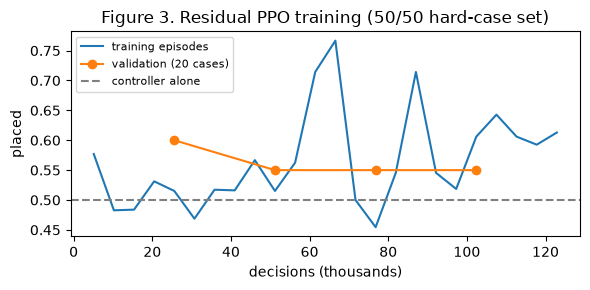

In [6]:
log = load("runs/insertion_mix/log.jsonl")
if log:
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot([r["decisions"] / 1000 for r in log], [r["train_success"] for r in log], label="training episodes")
    v = [(r["decisions"] / 1000, r["val_success"]) for r in log if "val_success" in r]
    if v: ax.plot(*zip(*v), "o-", label="validation (20 cases)")
    if base: ax.axhline(np.mean([b["outcome"] == "success" for b in base]), color="grey", ls="--", label="controller alone")
    ax.set_xlabel("decisions (thousands)"); ax.set_ylabel("placed"); ax.legend(fontsize=8)
    ax.set_title("Figure 3. Residual PPO training (50/50 hard-case set)"); plt.tight_layout()

With the camera, the controller fails only 2–6% of the insertions it reaches (Table 4a). Trained on a
natural distribution, a residual would see almost only successes, where any correction can only hurt. We
therefore train on a set balanced 50/50 between failures and successes, split by layout. On 20 validation
cases, the residual rescues 2 of the controller's 10 failures and loses none at its best checkpoint (Table
4b). This is not significant (p = 0.5). Because the same cases selected the checkpoint, the estimate is
optimistic. On a held-out pool of 24 cases from layouts never used in training or checkpoint selection
(12 of them labelled as controller failures, taken from 355 labelled cases), the controller alone places 15
and the residual places 15: it rescues 1 and loses 1.

Most of the camera's losses are out of the residual's reach. It acts during insertion only, so it cannot
fix an underestimated free space (53 of 175 lost rows) or a gap left too narrow (36). This is the main
difference from [2], whose nominal controller fails 73% of insertions, leaving much more for the residual
to fix.

**Increments vs targets.** A fixed policy that outputs a steady 0.1 on $x, y, z$ during insertion places 3
of 8 books when the action is an increment (four jam at the entrance, one is left 92 mm proud), and 8 of 8
when it is a target, as does the controller alone (notebook 05). This is the failure mode of our first
residual, which lost 12 of the 24 validation rows the controller placed.

### 5.5 Learned skill selection

In [7]:
R, Q = by_row(load("results/hl_eval_rules.jsonl")), by_row(load("results/hl_eval_q.jsonl"))
if R and Q:
    print("Table 5. Rules vs learned selector, seeds 0-24 per scenario, noisy-learned perception, paired\n")
    print(f"{'':9}{'rules':28}{'learned':28}")
    for s in SCEN:
        ks = [k for k in R if k[0] == s and k in Q]
        print(f"{s:9}{rate(sum(bool(R[k].get('success')) for k in ks), len(ks)):28}{rate(sum(bool(Q[k].get('success')) for k in ks), len(ks)):28}")
    n, only_r, only_q, p = paired(R, Q)
    print(f"\nall {n} rows: only rules {len(only_r)}, only learned {len(only_q)}; exact McNemar p = {p:.2g}")
    print(f"skills per row: rules {np.mean([len(r['steps']) for r in R.values()]):.2f}, learned {np.mean([len(r['steps']) for r in Q.values()]):.2f}")
cart = collections.defaultdict(dict)
p = ROOT / "results/hl_cart.txt"
for line in (open(p) if p.exists() else []):
    head, _, tail = line.partition("|"); s, seed, mode = head.split()
    cart[(s, int(seed))][mode] = tail.strip().startswith("SUCCESS")
if cart:
    print("\nfull cart pipeline (tray, labels, camera), 12 scenes:",
          ", ".join(f"{m} {sum(v.get(m, False) for v in cart.values())}/{len(cart)}" for m in ("rules", "policy")))

Table 5. Rules vs learned selector, seeds 0-24 per scenario, noisy-learned perception, paired

         rules                       learned                     
clear    96% [80–99] (24/25)         96% [80–99] (24/25)         
tight    72% [52–86] (18/25)         72% [52–86] (18/25)         
leaning  84% [65–94] (21/25)         84% [65–94] (21/25)         
packed   52% [33–70] (13/25)         52% [33–70] (13/25)         

all 100 rows: only rules 2, only learned 2; exact McNemar p = 1
skills per row: rules 2.25, learned 2.36

full cart pipeline (tray, labels, camera), 12 scenes: rules 10/12, policy 10/12


The learned selector ties the rules: 76 of 100 rows each (Table 5). It chooses differently on about half the
rows, but its wins and losses cancel. It shoves before standing up when a leaner is wedged and the rules
have run out of widenings, and it gives up less often. But it learned to skip some stand-ups, leaving a
leaner that later catches the book. On the full cart pipeline with the rendered camera, it transfers from
the noise model it was trained on: 10 of 12 scenes for both, failing the same two packed scenes on arm
reach. In tight rows it uses one `widen_more` where the rules widen two or three times. The training data
contain only 4 jams in 240 episodes, so `set_aside` was rarely exercised.

**Grasping without privileged information.** In the cart scenes the book is held by friction under the
gripper's 70 N squeeze, which measured 61–70 N per side throughout the carry. The robot grasps the tray book
where the tray's layout and the catalogue put it, and believes the book stays where the hand closed on it.
By the time the book is released that belief is 1.6–3.5 mm and 0.3–0.7° off, because the book shifts in
the grip on the way. The cart still places 10 of 12 scenes, the same as when the controller re-read the
book's true pose from the simulator three times during the carry; the two packed scenes fail on arm reach
before the grasp.

## 6. Discussion and Limitations

**Where books are lost.** With exact perception the controller fails 2.5% of box-book rows and 5.5% of
real-book rows. The camera adds 16 points on real books (21 on box books without pose correction), and
success falls steadily as its errors grow (Table 3b), through systematic errors (thickness bias summed along the row, calibration shift), not
segmentation. Arm reach accounts for the remaining packed failures. Neither error source is accessible to
an insertion residual or to the choice of skill. The two learned layers therefore have little to fix. This
is the reverse of [2], where a weak nominal controller leaves most of the gain to learning.

**What would help.** Correcting the thickness bias, for example by subtracting a calibrated edge spread or
using the catalogue's known thicknesses as the cart demo does, targets the largest loss directly. A residual
on the gap-creation skills (widen, shove), which our environment supports but we did not train, would act
where most failures occur.

**Limitations.**
- Everything is in simulation. The sim-to-real gap reported in [2] (98.5% to 63.3%) warns that contact
  effects, compliance and friction will cost more on hardware.
- Books are rigid apart from hinged pages; soft covers, the failure mode reported in [1], are not modelled.
- The hand-over of the book is not modelled in the controller experiments (it starts in the hand). In the
  cart demo, setting a jammed book aside returns it to the tray without simulating the carry.
- Test sets are small: 20 validation cases and a 24-case held-out pool for the residual, and 12 cart
  scenes.
- The grasp's friction is not calibrated. The pads' sliding friction (1.0) fits rubber pads on matte
  covers, and is optimistic for hard fingertips or glossy covers. Their torsional friction (0.05 m) is
  3–5 times what a 10 mm pad's contact patch gives, so heavy, deep books twist less in the grip than they
  would on hardware. The tray books also settle exactly where the tray puts them, which makes the grasp
  easier than a real tray.
- On macOS the renderer's depth is less precise than on Linux. Our real-book camera runs agree closely with
  a run on another machine, but small differences are expected.

## 7. Conclusion

We studied robotic reshelving including the step prior work assumes away: making room for the book. A
closed-loop controller over four gap-creation skills places 97.5% of books across clear, tight, leaning
and packed rows with exact perception, and 79% of real-book rows from a wrist RGB-D camera with learned segmentation. Success falls steadily as
the camera's errors grow, from 94.5% without them to 49.5% at twice their measured size. A residual PPO for insertion and a
learned skill selector did not significantly improve on the controller, because the remaining failures
come from perception and reach rather than from insertion or skill choice. Removing the camera's
systematic thickness bias and learning corrections for the gap-creation skills themselves are the most
direct next steps.

## References

1. B. Sygo, S.-C. Liu, F. Wieczorek, M. Koshil, M. Görner, N. Hendrich, J. Zhang. *Multi-Stage Book
   Perception and Bimanual Manipulation for Rearranging Book Shelves.* Springer, 2023/2024,
   doi:10.1007/978-3-031-44851-5_38. Preprint: *Trixi the Librarian*, arXiv:2210.10110. Code:
   github.com/TAMS-Group/PBBM-robot-librarian.
2. T. Liu, R. A. Patamia, B. Champion, A. Cosgun, R. Dazeley. *Hybrid Residual Reinforcement Learning for
   Contact-Rich Robotic Book Insertion.* arXiv:2609.19962, 2026.
3. T. Johannink, S. Bahl, A. Nair, J. Luo, A. Kumar, M. Loskyll, J. A. Ojea, E. Solowjow, S. Levine.
   *Residual Reinforcement Learning for Robot Control.* ICRA 2019.
4. T. Silver, K. Allen, J. Tenenbaum, L. Kaelbling. *Residual Policy Learning.* arXiv:1812.06298, 2018.
5. M. Dalal, D. Pathak, R. Salakhutdinov. *Accelerating Robotic Reinforcement Learning via Parameterized
   Action Primitives (RAPS).* NeurIPS 2021.
6. S. Nasiriany, H. Liu, Y. Zhu. *Augmenting Reinforcement Learning with Behavior Primitives for Diverse
   Manipulation Tasks (MAPLE).* ICRA 2022.
7. D. Ernst, P. Geurts, L. Wehenkel. *Tree-Based Batch Mode Reinforcement Learning.* JMLR 2005.
8. M. Riedmiller. *Neural Fitted Q Iteration.* ECML 2005.
9. K. He, G. Gkioxari, P. Dollár, R. Girshick. *Mask R-CNN.* ICCV 2017.
10. S. Garrido-Jurado, R. Muñoz-Salinas, F. J. Madrid-Cuevas, M. J. Marín-Jiménez. *Automatic Generation and
    Detection of Highly Reliable Fiducial Markers under Occlusion.* Pattern Recognition, 2014.
11. L. Pinto, M. Andrychowicz, P. Welinder, W. Zaremba, P. Abbeel. *Asymmetric Actor Critic for Image-Based
    Robot Learning.* RSS 2018.
12. J. Schulman, F. Wolski, P. Dhariwal, A. Radford, O. Klimov. *Proximal Policy Optimization Algorithms.*
    arXiv:1707.06347, 2017.
13. E. Todorov, T. Erez, Y. Tassa. *MuJoCo: A Physics Engine for Model-Based Control.* IROS 2012.

**Library statistics:** NLB Year in Review 2022 (25.6M physical loans); Y. C. Liau, IFLA WLIC 2019
(shelf-reading robots hand misplaced books to staff).